# Search Engine From Scratch
An inverted-index search engine with boolean queries and TF-IDF / BM25 ranking.


In [1]:
import re, math, time, heapq
from collections import defaultdict, Counter

## 1. Load the data
20 Newsgroups: about 18k posts across 20 topics. Each document's id is its position in `docs`.

In [2]:
from sklearn.datasets import fetch_20newsgroups

raw = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes"))
docs, labels = [], []
for text, target in zip(raw.data, raw.target):
    if len(text.split()) >= 20:  # drop empty / tiny posts
        docs.append(text)
        labels.append(raw.target_names[target])
print(f"{len(docs):,} documents")

16,779 documents


## 2. Tokenizer and stemmer
Lowercase, split into alphanumeric words, drop stop words, then stem
("foxes" and "fox" both become "fox"). Queries go through the same pipeline as documents.

In [3]:
from nltk.stem import PorterStemmer

STOP_WORDS = set("""a about above after again all also am an and any are as at be because been before being below
between both but by can could did do does doing down during each few for from further had has have having he her
here hers him his how i if in into is it its just me more most my no nor not now of off on once only or other our
out over own same she should so some such than that the their them then there these they this those through to too
under until up very was we were what when where which while who whom why will with would you your""".split())

_stemmer = PorterStemmer()
_stem_cache = {}

def stem(word):
    s = _stem_cache.get(word)
    if s is None:
        s = _stem_cache[word] = _stemmer.stem(word)
    return s

def tokenize(text):
    """lowercase -> alphanumeric words -> drop stop words -> stem"""
    return [stem(w) for w in re.findall(r"[a-z0-9]+", text.lower()) if w not in STOP_WORDS]

print(tokenize("The quick brown foxes are running!"))

['quick', 'brown', 'fox', 'run']


## 3. Inverted index
For every term we store the sorted list of document ids that contain it, plus the
positions of the term inside each document (positions are not used yet, but they
are what phrase search needs later).

In [4]:
class InvertedIndex:
    def __init__(self):
        self.ids = defaultdict(list)   # term -> [doc_id, ...] ascending
        self.pos = defaultdict(list)   # term -> [[positions in doc], ...] parallel to ids
        self.doc_len = {}              # doc_id -> number of indexed tokens
        self.n_docs = 0
        self.avg_len = 0.0
        self.norms = {}                # doc_id -> TF-IDF vector length (for cosine normalization)
        self._last_id = -1

    def add(self, doc_id, text):
        assert doc_id > self._last_id, "documents must be added in ascending id order"
        self._last_id = doc_id
        tokens = tokenize(text)
        self.doc_len[doc_id] = len(tokens)
        positions = defaultdict(list)
        for i, term in enumerate(tokens):
            positions[term].append(i)
        for term, plist in positions.items():
            self.ids[term].append(doc_id)   # stays sorted because ids are added in order
            self.pos[term].append(plist)

    def finalize(self):
        """Call once after all documents are added."""
        self.n_docs = len(self.doc_len)
        self.avg_len = sum(self.doc_len.values()) / max(1, self.n_docs)
        sq = defaultdict(float)
        for term, ids in self.ids.items():
            idf = math.log(self.n_docs / len(ids))
            for d, plist in zip(ids, self.pos[term]):
                sq[d] += ((1 + math.log(len(plist))) * idf) ** 2
        self.norms = {d: math.sqrt(v) or 1.0 for d, v in sq.items()}

## 4. Boolean search
Merging two sorted lists takes O(m + n) instead of checking every document.
Query grammar: `NOT` binds tighter than `AND`, which binds tighter than `OR`.
Parentheses work, and two adjacent terms mean AND. Operators must be uppercase.

In [5]:
def intersect(a, b):
    i = j = 0
    out = []
    while i < len(a) and j < len(b):
        if a[i] == b[j]:
            out.append(a[i]); i += 1; j += 1
        elif a[i] < b[j]:
            i += 1
        else:
            j += 1
    return out

def union(a, b):
    i = j = 0
    out = []
    while i < len(a) and j < len(b):
        if a[i] == b[j]:
            out.append(a[i]); i += 1; j += 1
        elif a[i] < b[j]:
            out.append(a[i]); i += 1
        else:
            out.append(b[j]); j += 1
    out.extend(a[i:])
    out.extend(b[j:])
    return out

def difference(a, b):
    """a AND NOT b"""
    i = j = 0
    out = []
    while i < len(a):
        if j == len(b) or a[i] < b[j]:
            out.append(a[i]); i += 1
        elif a[i] == b[j]:
            i += 1; j += 1
        else:
            j += 1
    return out


class BooleanSearcher:
    """Recursive-descent parser:
         expr   := term (OR term)*
         term   := factor ((AND)? factor)*
         factor := NOT factor | ( expr ) | WORD
    A word that is only a stop word (e.g. "the") returns None, meaning "ignore me"."""

    def __init__(self, index):
        self.index = index
        self.all_docs = sorted(index.doc_len)

    def search(self, query):
        self.toks = re.findall(r"\(|\)|[^\s()]+", query)
        self.i = 0
        return self._expr() or []

    def _peek(self):
        return self.toks[self.i] if self.i < len(self.toks) else None

    @staticmethod
    def _combine(a, b, op):
        if a is None: return b
        if b is None: return a
        return op(a, b)

    def _expr(self):
        left = self._term()
        while self._peek() == "OR":
            self.i += 1
            left = self._combine(left, self._term(), union)
        return left

    def _term(self):
        left = self._factor()
        while self._peek() not in (None, "OR", ")"):
            if self._peek() == "AND":
                self.i += 1
            left = self._combine(left, self._factor(), intersect)
        return left

    def _factor(self):
        tok = self._peek()
        if tok is None:
            return None
        if tok == "NOT":
            self.i += 1
            inner = self._factor()
            return None if inner is None else difference(self.all_docs, inner)
        if tok == "(":
            self.i += 1
            inner = self._expr()
            if self._peek() == ")":
                self.i += 1
            return inner
        self.i += 1
        result = None
        for term in tokenize(tok):
            result = self._combine(result, self.index.ids.get(term, []), intersect)
        return result

## 5. Ranked search: TF-IDF and BM25
Both are computed term-at-a-time: walk the posting list of each query term and
accumulate a score per document, then take the top k with a heap.

- **TF-IDF**: weight = (1 + log tf) × idf, cosine-normalized by the document's vector length.
- **BM25**: saturating term frequency plus document-length normalization (k1 = 1.5, b = 0.75).

In [6]:
def tfidf_search(index, query, k=10):
    scores = defaultdict(float)
    for term, qtf in Counter(tokenize(query)).items():
        ids = index.ids.get(term)
        if not ids:
            continue
        idf = math.log(index.n_docs / len(ids))
        q_weight = (1 + math.log(qtf)) * idf
        for d, plist in zip(ids, index.pos[term]):
            scores[d] += (1 + math.log(len(plist))) * idf * q_weight
    for d in scores:
        scores[d] /= index.norms[d]
    return heapq.nlargest(k, scores.items(), key=lambda x: x[1])


def bm25_search(index, query, k=10, k1=1.5, b=0.75):
    scores = defaultdict(float)
    N = index.n_docs
    for term in set(tokenize(query)):
        ids = index.ids.get(term)
        if not ids:
            continue
        df = len(ids)
        idf = math.log(1 + (N - df + 0.5) / (df + 0.5))
        for d, plist in zip(ids, index.pos[term]):
            tf = len(plist)
            length_norm = k1 * (1 - b + b * index.doc_len[d] / index.avg_len)
            scores[d] += idf * tf * (k1 + 1) / (tf + length_norm)
    return heapq.nlargest(k, scores.items(), key=lambda x: x[1])


class SearchEngine:
    def __init__(self, docs):
        self.docs = docs
        self.index = InvertedIndex()
        for i, text in enumerate(docs):
            self.index.add(i, text)
        self.index.finalize()
        self.boolean = BooleanSearcher(self.index)

    def search_boolean(self, query):
        return self.boolean.search(query)

    def search(self, query, method="bm25", k=10):
        fn = {"bm25": bm25_search, "tfidf": tfidf_search}[method]
        return fn(self.index, query, k)


def make_snippet(text, query, width=160):
    """Show the text around the first word that matches the query."""
    terms = set(tokenize(query))
    for m in re.finditer(r"[A-Za-z0-9]+", text):
        if stem(m.group().lower()) in terms:
            start, end = max(0, m.start() - width // 2), min(len(text), m.end() + width // 2)
            return ("…" if start else "") + " ".join(text[start:end].split()) + ("…" if end < len(text) else "")
    return " ".join(text[:width].split())

## 6. Unit tests
Always test on a tiny corpus where you can verify the answers by hand.

In [7]:
assert intersect([1, 3, 5, 7], [3, 4, 5, 8]) == [3, 5]
assert union([1, 3, 5, 7], [3, 4, 5, 8]) == [1, 3, 4, 5, 7, 8]
assert difference([1, 3, 5, 7], [3, 5]) == [1, 7]
assert intersect([], [1, 2]) == [] and union([], [1, 2]) == [1, 2] and difference([1, 2], []) == [1, 2]

mini = SearchEngine([
    "The quick brown fox",        # 0
    "The lazy dog",               # 1
    "Quick brown dogs and foxes", # 2
    "Cats and dogs",              # 3
])

assert mini.search_boolean("quick AND fox") == [0, 2]
assert mini.search_boolean("quick fox") == [0, 2]            # implicit AND
assert mini.search_boolean("fox OR cat") == [0, 2, 3]
assert mini.search_boolean("dog AND NOT lazy") == [2, 3]
assert mini.search_boolean("(fox OR cat) AND quick") == [0, 2]
assert mini.search_boolean("NOT dog") == [0]
assert mini.search_boolean("the AND fox") == [0, 2]          # stop word ignored
assert mini.search_boolean("unicorn") == []

for method in ("bm25", "tfidf"):
    res = mini.search("quick fox", method)
    ids = [d for d, _ in res]
    assert res[0][0] in (0, 2), method
    assert 1 not in ids and 3 not in ids, method              # no matching terms
    assert [s for _, s in res] == sorted((s for _, s in res), reverse=True)

print("All tests passed ✓")

All tests passed ✓


## 7. Build the real index and try it

In [8]:
t0 = time.perf_counter()
engine = SearchEngine(docs)
print(f"Indexed {engine.index.n_docs:,} docs, {len(engine.index.ids):,} unique terms "
      f"in {time.perf_counter() - t0:.1f}s")

def show(results, query, n=5):
    for d, score in results[:n]:
        print(f"  [{score:6.3f}] #{d} ({labels[d]})")
        print(f"      {make_snippet(docs[d], query)}")

query = "space shuttle launch"
print(f'\nBM25 for "{query}":')
show(engine.search(query, "bm25"), query)
print(f'\nTF-IDF for "{query}":')
show(engine.search(query, "tfidf"), query)

bq = "(nasa OR shuttle) AND launch AND NOT moon"
hits = engine.search_boolean(bq)
print(f'\nBoolean "{bq}": {len(hits)} matching docs, first ids: {hits[:10]}')

Indexed 16,779 docs, 107,555 unique terms in 8.8s

BM25 for "space shuttle launch":
  [23.327] #11482 (sci.space)
      This notice will be posted weekly in sci.space, sci.astro, and sci.space.shuttle. The Frequently Asked Questions (FAQ) li…
  [21.896] #1864 (sci.space)
      For an essay, I am writing about the space shuttle and a need for a better propulsion system. Through research, I have fo…
  [21.784] #13474 (sci.space)
      …rry for asking a question that's not entirely based on the technical aspects of space, but I couldn't find the answer on the FAQs ! I'm currently in the UK, which m…
  [20.738] #11496 (sci.space)
      : >the Single Launch Core Station concept. A Shuttle external tank and solid : >rocket boosters wou…
  [19.890] #11640 (sci.space)
      From another space forum When workers at the Kennedy Space Center disassembled the STS-56 sol…

TF-IDF for "space shuttle launch":
  [ 3.513] #7573 (sci.space)
      Well, you better not get the shuttle as your launch vehic

## 8. Benchmark: inverted index vs. scanning every document
The naive version checks every document's term set. The index only touches the
posting lists of the query terms, so its cost depends on how many docs contain those
terms, not on corpus size.

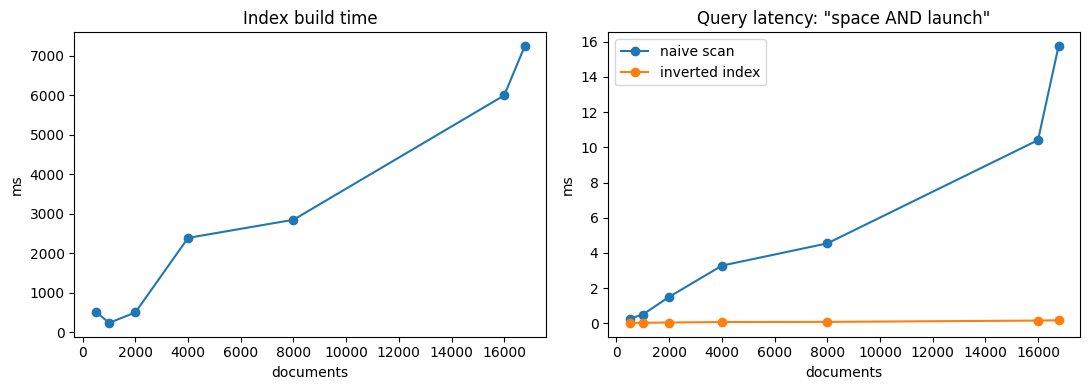

   500 docs: scan    0.256 ms | index  0.0182 ms |     14x faster
  1000 docs: scan    0.495 ms | index  0.0253 ms |     20x faster
  2000 docs: scan    1.498 ms | index  0.0400 ms |     37x faster
  4000 docs: scan    3.273 ms | index  0.0669 ms |     49x faster
  8000 docs: scan    4.538 ms | index  0.0750 ms |     61x faster
 16000 docs: scan   10.411 ms | index  0.1496 ms |     70x faster
 16779 docs: scan   15.751 ms | index  0.1661 ms |     95x faster


In [9]:
import matplotlib.pyplot as plt

def timeit_ms(fn, repeats=30):
    t0 = time.perf_counter()
    for _ in range(repeats):
        fn()
    return (time.perf_counter() - t0) / repeats * 1000

q_terms = tokenize("space launch")
sizes = sorted({n for n in (500, 1000, 2000, 4000, 8000, 16000, len(docs)) if n <= len(docs)})
build_ms, index_ms, scan_ms = [], [], []

for n in sizes:
    sub = docs[:n]
    t0 = time.perf_counter()
    eng = SearchEngine(sub)
    build_ms.append((time.perf_counter() - t0) * 1000)
    token_sets = [set(tokenize(d)) for d in sub]
    index_ms.append(timeit_ms(lambda: eng.search_boolean("space AND launch")))
    scan_ms.append(timeit_ms(lambda: [i for i, s in enumerate(token_sets) if all(t in s for t in q_terms)]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sizes, build_ms, marker="o")
axes[0].set(title="Index build time", xlabel="documents", ylabel="ms")
axes[1].plot(sizes, scan_ms, marker="o", label="naive scan")
axes[1].plot(sizes, index_ms, marker="o", label="inverted index")
axes[1].set(title='Query latency: "space AND launch"', xlabel="documents", ylabel="ms")
axes[1].legend()
plt.tight_layout()
plt.show()

for n, s, i in zip(sizes, scan_ms, index_ms):
    print(f"{n:>6} docs: scan {s:8.3f} ms | index {i:7.4f} ms | {s / max(i, 1e-9):6.0f}x faster")

## 9. Search box demo
Pick a mode, type a query, press Search (or hit Enter).

In [10]:
import ipywidgets as widgets
from IPython.display import display, clear_output

box = widgets.Text(placeholder="e.g. space shuttle launch   |   boolean: (nasa OR shuttle) AND NOT moon",
                   description="Query:", layout=widgets.Layout(width="90%"))
mode = widgets.ToggleButtons(options=["BM25", "TF-IDF", "Boolean"], description="Mode:")
btn = widgets.Button(description="Search", button_style="primary")
out = widgets.Output()

def run_search(_=None):
    with out:
        clear_output()
        q = box.value.strip()
        if not q:
            return
        t0 = time.perf_counter()
        if mode.value == "Boolean":
            ids = engine.search_boolean(q)
            ms = (time.perf_counter() - t0) * 1000
            print(f"{len(ids):,} matches in {ms:.2f} ms (showing first 10)\n")
            hits = [(d, None) for d in ids[:10]]
        else:
            hits = engine.search(q, "bm25" if mode.value == "BM25" else "tfidf")
            ms = (time.perf_counter() - t0) * 1000
            print(f"{len(hits)} results in {ms:.2f} ms\n")
        for d, s in hits:
            score = "" if s is None else f"score {s:.2f} | "
            print(f"#{d}  [{labels[d]}]  {score}")
            print("    " + make_snippet(docs[d], q) + "\n")

btn.on_click(run_search)
box.on_submit(run_search)
display(box, mode, btn, out)

Text(value='', description='Query:', layout=Layout(width='90%'), placeholder='e.g. space shuttle launch   |   …

ToggleButtons(description='Mode:', options=('BM25', 'TF-IDF', 'Boolean'), value='BM25')

Button(button_style='primary', description='Search', style=ButtonStyle())

Output()